# PWL Switch-Onset Loss Scan

This notebook loads a trained AL-RNN and investigates **why it can sense regime changes** from the perspective of the ITF loss landscape.

### Background

An AL-RNN with P PWL units defines **2^P piecewise-linear dynamical systems**, one per bitcode pattern.  
Inside `model.forward`, the ReLU acts on the incoming pre-activation `h[-P:]`:

```
relu_out[-P:] = relu(h[-P:])   →   0         if h[-P+i] < 0  (bitcode i = 0)
                                    h[-P+i]   if h[-P+i] > 0  (bitcode i = 1)
```

The **effective W matrix** therefore differs between bitcodes — when bit i = 0 the i-th column of W is gated out.  
The model learns one dominant bitcode per regime; the switch between them at the regime change is what drives the reconstruction-loss improvement.

### Analysis plan

1. **Natural run** — inspect the bitcode trajectory and per-step MSE  
2. **Effective connectivity** — visualise W_full vs W_inactive and the delta columns  
3. **Bitcode-forced loss scan** — for each candidate switch time t*, force `bc_pre → bc_post` and measure total MSE  
4. **Per-step loss breakdown** — MSE at each t coloured by the current bitcode

In [108]:
import os, sys
sys.path.insert(0, os.path.abspath("..") if os.path.basename(os.getcwd()) != "al_rnn_nonstationarity" else ".")

import numpy as np
import torch
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

from alrnn.model import AL_RNN
from analysis.pwl_switch_scan import (
    natural_run, bitcode_forced_scan, plot_scan_result, effective_w_matrices,
)

## Configuration

Set `CHECKPOINT` to the `.pt` file saved by `run_var.py` or `run_lorenz.py`.

In [109]:
#CHECKPOINT = "experiments/var_results/critical_slowing_model.pt"
CHECKPOINT = "experiments/var_results/modular_to_hub_model.pt"
#CHECKPOINT = "experiments/sinusoid_results/alignment_model.pt"
#CHECKPOINT = "experiments/sinusoid_results/alignment_ss0.6_fr0.1-0.2_model.pt"
CHECKPOINT = "experiments/sinusoid_results//alignment_ss0.4_fr0.03-0.3_model.pt"

#CHECKPOINT = "experiments/lorenz_results/lorenz_model.pt"
DEVICE     = "cpu"

## Load model + data

In [110]:
ckpt = torch.load(CHECKPOINT, map_location=DEVICE, weights_only=False)

model = AL_RNN(
    M=ckpt["M"], P=ckpt["P"], N=ckpt["N"], d_input=ckpt["d_input"],
    temporal_input_target=ckpt["config"].get("temporal_input_target", "all"),
).to(DEVICE)
model.load_state_dict(ckpt["model_state_dict"])
model.eval()

cfg           = ckpt["config"]
train_series  = ckpt["train_series"]    # standardised (T, N)
time_series   = ckpt["time_series"]     # original     (T, N)
mean          = np.array(ckpt["mean"])
std           = np.array(ckpt["std"])
switch_times  = np.array(ckpt["switch_times"])
segment_ids   = np.array(ckpt["segment_ids"])
ext_inputs    = ckpt["external_inputs"]   # (T, d_input) or None

T, N = train_series.shape
print(f"Loaded: M={model.M}, P={model.P}, N={model.N}, T={T}, switch_times={switch_times.tolist()}")
print(f"Config: forcing_mode={cfg['forcing_mode']!r}, n_interleave={cfg['n_interleave']}, "
      f"end_alpha={cfg.get('end_alpha')}, temporal_input_target={cfg.get('temporal_input_target', 'all')!r}")

# Build full-sequence tensors
x_full = torch.tensor(train_series, dtype=torch.float32).unsqueeze(0)   # (1, T, N)
u_full = (torch.tensor(ext_inputs,  dtype=torch.float32).unsqueeze(0)
          if ext_inputs is not None else None)

vis_alpha        = cfg.get("end_alpha") if cfg.get("end_alpha") is not None else cfg["alpha"]
vis_n_interleave = cfg.get("n_interleave", 1)

Loaded: M=20, P=2, N=5, T=800, switch_times=[300, 500]
Config: forcing_mode='itf', n_interleave=4, end_alpha=1.0, temporal_input_target='monotone_gate'


---
## 1. Natural run — bitcode trajectory and per-step MSE

In [111]:
nat = natural_run(model, x_full, u=u_full, alpha=vis_alpha, n_interleave=vis_n_interleave)

print(f"Natural ITF MSE = {nat['total_mse']:.6f}")
print(f"PWL pre-activation shape: {nat['pwl_preact'].shape}   bitcodes shape: {nat['bitcodes'].shape}")

# Dominant bitcode in each half
mid = T // 2
bc_first_half = (nat["bitcodes"][:mid].mean(axis=0) >= 0.5).astype(int)
bc_second_half = (nat["bitcodes"][mid:].mean(axis=0) >= 0.5).astype(int)
print(f"Dominant bitcode  first half : {bc_first_half.tolist()}")
print(f"Dominant bitcode  second half: {bc_second_half.tolist()}")

Natural ITF MSE = 0.555610
PWL pre-activation shape: (800, 2)   bitcodes shape: (800, 2)
Dominant bitcode  first half : [0, 0]
Dominant bitcode  second half: [1, 1]


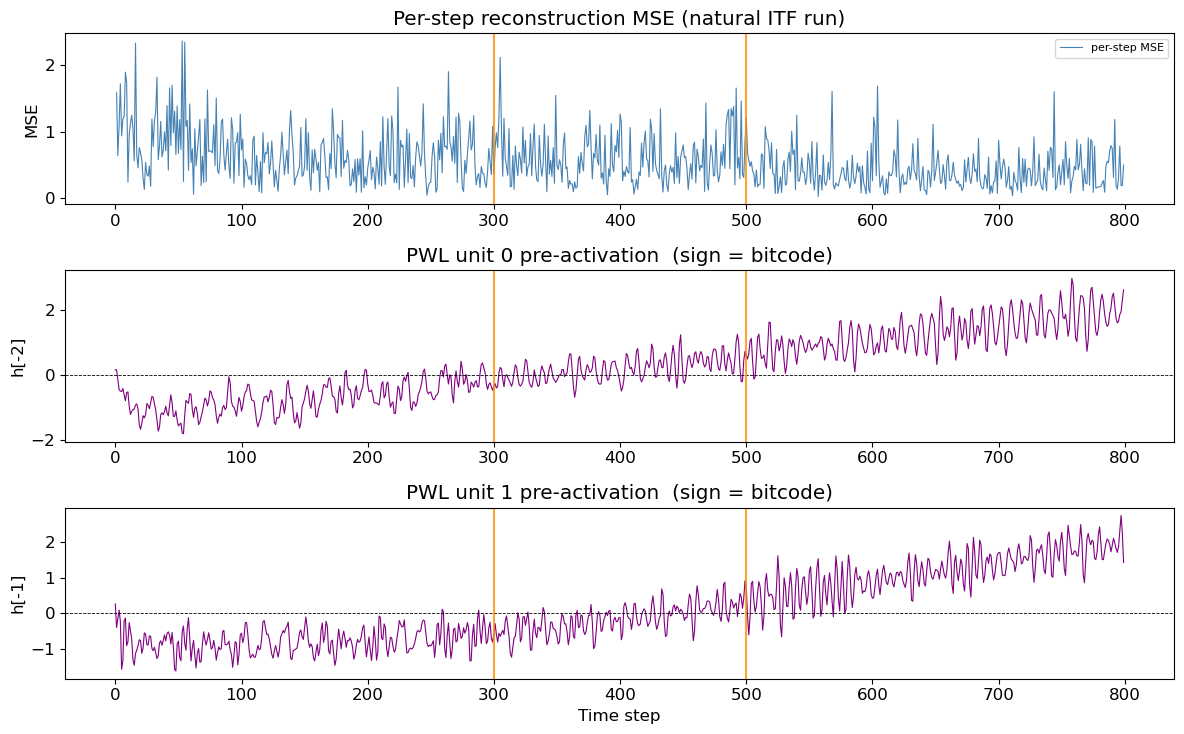

In [112]:
P = model.P
n_rows = P + 1
fig = plt.figure(figsize=(12, 2.5 * n_rows))

# Per-step MSE
ax0 = fig.add_subplot(n_rows, 1, 1)
t_mse = np.arange(1, T)
ax0.plot(t_mse, nat["per_step_mse"], lw=0.8, color="steelblue", label="per-step MSE")
ax0.set_ylabel("MSE")
ax0.set_title("Per-step reconstruction MSE (natural ITF run)")
for gt in switch_times:
    ax0.axvline(gt, color="darkorange", lw=1.5, ls="-", alpha=0.8)
ax0.legend(fontsize=8)

# Pre-activation for each PWL unit
axs = [ax0]
for i in range(P):
    ax = fig.add_subplot(n_rows, 1, i + 2, sharex=ax0)
    preact = nat["pwl_preact"][:, i]
    ax.plot(preact, lw=0.8, color="purple")
    ax.axhline(0, color="k", lw=0.6, ls="--")
    ax.set_ylabel(f"h[{-P+i}]")
    ax.set_title(f"PWL unit {i} pre-activation  (sign = bitcode)")
    for gt in switch_times:
        ax.axvline(gt, color="darkorange", lw=1.5, ls="-", alpha=0.8)
    axs.append(ax)

axs[-1].set_xlabel("Time step")
fig.tight_layout()
plt.show()

---
## 2. Effective connectivity — W matrices per bitcode region

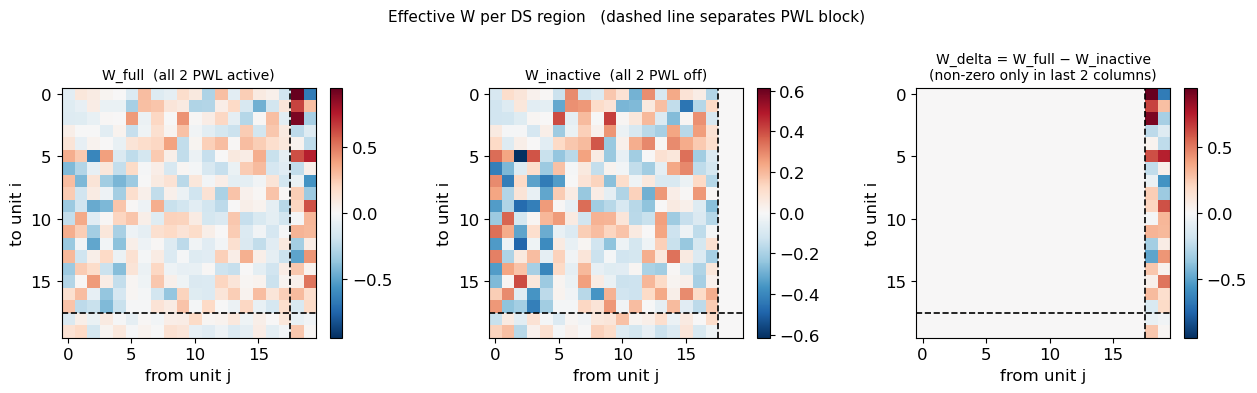


W_delta Frobenius norm : 2.4706
W_full  Frobenius norm : 4.2859


In [113]:
wm = effective_w_matrices(model)

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
M = model.M

def _wplot(ax, W, title):
    vmax = max(abs(W).max(), 1e-6)
    im = ax.imshow(W, cmap="RdBu_r", vmin=-vmax, vmax=vmax, aspect="auto")
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("from unit j")
    ax.set_ylabel("to unit i")
    # Mark PWL region
    P = model.P
    ax.axhline(M - P - 0.5, color="k", lw=1.2, ls="--")
    ax.axvline(M - P - 0.5, color="k", lw=1.2, ls="--")
    plt.colorbar(im, ax=ax, fraction=0.046)

_wplot(axes[0], wm["W_full"],     f"W_full  (all {P} PWL active)")
_wplot(axes[1], wm["W_inactive"], f"W_inactive  (all {P} PWL off)")
_wplot(axes[2], wm["W_delta"],    f"W_delta = W_full − W_inactive\n(non-zero only in last {P} columns)")

fig.suptitle("Effective W per DS region   (dashed line separates PWL block)", fontsize=11)
fig.tight_layout()
plt.show()

print(f"\nW_delta Frobenius norm : {np.linalg.norm(wm['W_delta']):.4f}")
print(f"W_full  Frobenius norm : {np.linalg.norm(wm['W_full']):.4f}")

The **last P columns** of W (`W_delta`) encode the incremental connectivity that is added when a PWL unit is active.  
If these columns are non-trivial, the two DSs genuinely differ in their dynamics.

---
## 3. Bitcode-forced loss scan

For each candidate switch time t*, force:
- `h[-P:] sign = bc_pre`  for t < t*  (DS of regime 1)
- `h[-P:] sign = bc_post` for t ≥ t*  (DS of regime 2)

Compute total MSE.  Expected: minimum near the true switch time.

In [114]:
# Select which PWL units to analyse.
# With P=1 there is only one unit; with P=4 inspect the natural run above
# (section 1) to identify which unit(s) show a clean sign-flip near the
# regime change, then list them here (0-based index within the P units).
# None = use all P units.
PWL_UNITS = None   # e.g. [0] or [2, 3]

scan = bitcode_forced_scan(
    model, x_full, u=u_full,
    alpha=vis_alpha,
    n_interleave=4,
    step=10,
    pwl_units=PWL_UNITS,
    # bc_pre  = np.array([0]),   # override auto-detection if needed
    # bc_post = np.array([1]),
)
print(f"\nScan complete.")
print(f"  pwl_units       : {scan['pwl_units']}")
print(f"  Natural MSE     : {scan['loss_natural']:.6f}")
print(f"  Always bc_pre   : {scan['loss_always_pre']:.6f}")
print(f"  Always bc_post  : {scan['loss_always_post']:.6f}")
best_t = scan["switch_times"][np.argmin(scan["scan_losses"])]
print(f"  Scan minimum t* : {best_t}  (ground-truth: {switch_times.tolist()})")


  pwl_units=[0, 1]  bc_pre=[0, 0]  bc_post=[1, 1]

Scan complete.
  pwl_units       : [0, 1]
  Natural MSE     : 0.555610
  Always bc_pre   : 0.743331
  Always bc_post  : 0.602021
  Scan minimum t* : 290  (ground-truth: [300, 500])


In [115]:
def plot_scan_result(
    scan,
    switch_times_gt,
    save_path,
) -> None:

    t_star  = scan["switch_times"]
    losses  = scan["scan_losses"]
    l_nat   = scan["loss_natural"]
    l_pre   = scan["loss_always_pre"]
    l_post  = scan["loss_always_post"]

    best_idx  = int(np.argmin(losses))
    best_t    = t_star[best_idx]
    best_loss = losses[best_idx]

    fig, ax = plt.subplots(figsize=(10, 5))

    ax.plot(t_star, losses, color="steelblue", lw=1.5,
            label=f"Forced-transition loss")
    ax.axhline(l_nat,  color="gray",     lw=1.2, ls="-.",
               label=f"Unforced Loss")
    ax.axhline(l_pre,  color="seagreen", lw=1.2, ls="--",
               label=f"Always BC_pre={scan['bc_pre'].tolist()}")
    ax.axhline(l_post, color="tomato",   lw=1.2, ls="--",
               label=f"Always BC_post={scan['bc_post'].tolist()}")
    ax.axvline(best_t, color="steelblue", lw=1.0, ls=":", alpha=0.8,
               label="Minimum")
    ax.scatter([best_t], [best_loss], color="steelblue", zorder=5, s=50)

    if switch_times_gt is not None:
        for i, gt in enumerate(np.atleast_1d(switch_times_gt)):
            ax.axvline(gt, color="black", lw=1.5, ls="-", alpha=0.85,
                       label="GT Switch" if i == 0 else None)

    ax.set_xlabel("Forced switch time  t*")
    ax.set_ylabel("Reconstruction MSE")
    ax.legend(fontsize=10, loc="lower right")
    fig.tight_layout()

    if save_path:
        fig.savefig(save_path, dpi=150)
    plt.show()


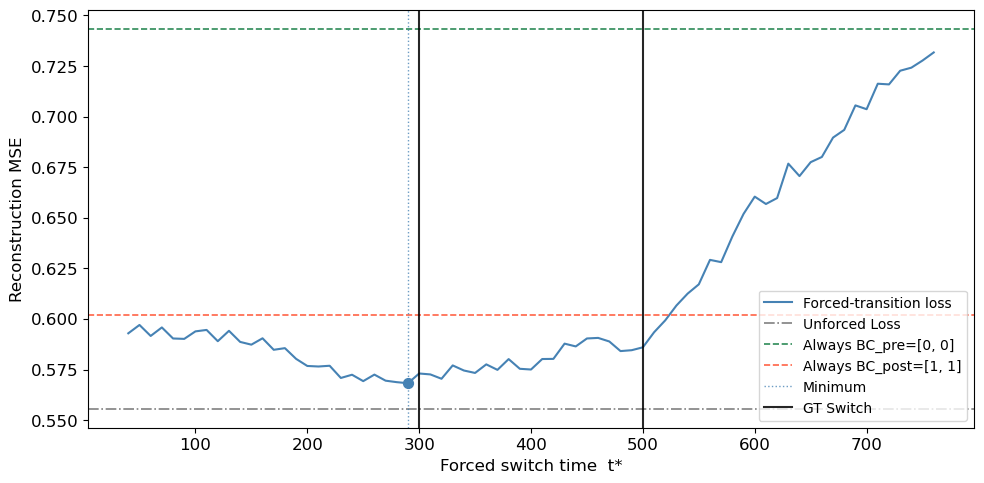

In [116]:
plt.rcParams['font.size'] = 12
plot_scan_result(
    scan,
    switch_times_gt=switch_times,
    save_path=None,
)

---
## 4. Per-step loss breakdown — natural vs forced regimes

In [104]:
# Re-run with bc_pre / bc_post to get per-step losses for each forced scenario
from analysis.pwl_switch_scan import _forced_run, _force_sign

def forced_per_step(model, x_full, u_full, alpha, n_interleave, bc_seq):
    """Return (T-1,) per-step MSE array for a given bc_seq (T, P)."""
    x_ = x_full.permute(1, 0, 2)
    u_ = u_full.permute(1, 0, 2) if u_full is not None else None
    T_loc = x_.shape[0]
    target = x_[1:, 0, :].cpu()
    N_loc, P_loc = model.N, model.P

    with torch.no_grad():
        h = model.obs_to_latent(x_[0])[:, N_loc:].detach().clone()
        h = _force_sign(h, bc_seq[0], P_loc)
        z_out = model(torch.cat([x_[0], h], dim=1),
                      u=u_[0] if u_ is not None else None)
        pred_list = [z_out[:, :N_loc]]
        h = z_out[:, N_loc:]

        for t in range(1, T_loc):
            h = _force_sign(h, bc_seq[t], P_loc)
            obs = (alpha * x_[t] + (1 - alpha) * z_out[:, :N_loc]
                   if t % n_interleave == 0 else z_out[:, :N_loc])
            z_out = model(torch.cat([obs, h], dim=1),
                          u=u_[t] if u_ is not None else None)
            pred_list.append(z_out[:, :N_loc])
            h = z_out[:, N_loc:]

        preds = torch.cat(pred_list[:-1], dim=0)
    return ((preds - target) ** 2).mean(dim=1).numpy()


bc_pre_arr  = np.tile(scan["bc_pre"],  (T, 1))
bc_post_arr = np.tile(scan["bc_post"], (T, 1))

mse_always_pre  = forced_per_step(model, x_full, u_full, vis_alpha, vis_n_interleave, bc_pre_arr)
mse_always_post = forced_per_step(model, x_full, u_full, vis_alpha, vis_n_interleave, bc_post_arr)

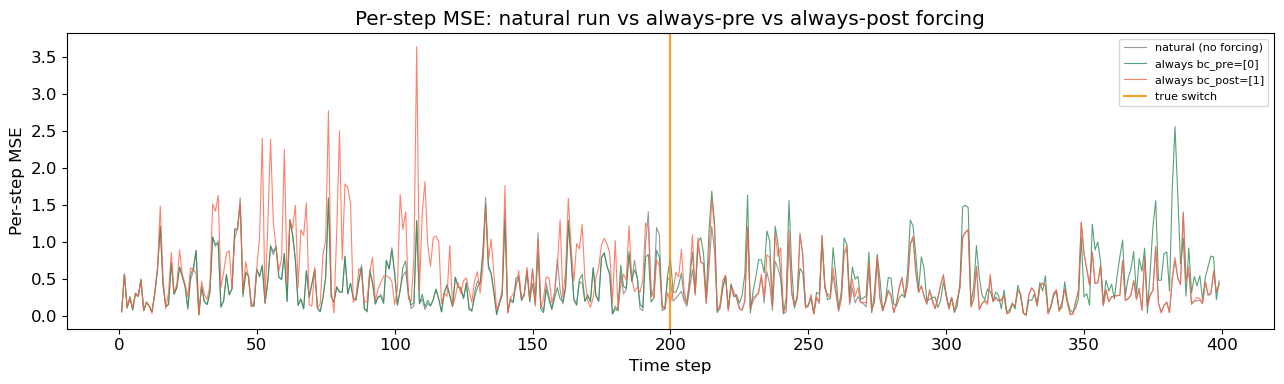

In [105]:
t_ax = np.arange(1, T)

fig, ax = plt.subplots(figsize=(13, 4))

ax.plot(t_ax, nat["per_step_mse"], lw=0.8, color="gray",    alpha=0.8, label="natural (no forcing)")
ax.plot(t_ax, mse_always_pre,      lw=0.8, color="seagreen", alpha=0.8, label=f"always bc_pre={scan['bc_pre'].tolist()}")
ax.plot(t_ax, mse_always_post,     lw=0.8, color="tomato",   alpha=0.8, label=f"always bc_post={scan['bc_post'].tolist()}")

for gt in switch_times:
    ax.axvline(gt, color="darkorange", lw=1.5, ls="-", alpha=0.85, label="true switch" if gt == switch_times[0] else None)

ax.set_xlabel("Time step")
ax.set_ylabel("Per-step MSE")
ax.set_title("Per-step MSE: natural run vs always-pre vs always-post forcing")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

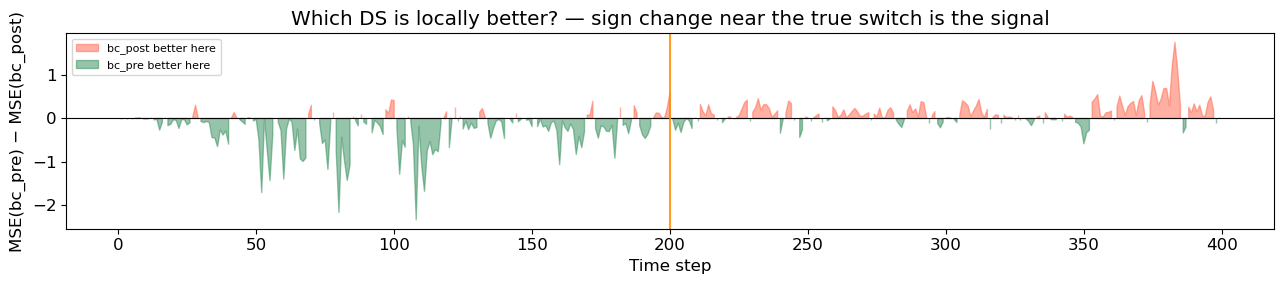

In [106]:
# Difference: (always_pre - always_post) per step
# Positive = bc_pre is worse; Negative = bc_post is worse
delta = mse_always_pre - mse_always_post

fig, ax = plt.subplots(figsize=(13, 3))
ax.fill_between(t_ax, 0, delta, where=(delta > 0),
                color="tomato",   alpha=0.5, label="bc_post better here")
ax.fill_between(t_ax, 0, delta, where=(delta < 0),
                color="seagreen", alpha=0.5, label="bc_pre better here")
ax.axhline(0, color="k", lw=0.8)
for gt in switch_times:
    ax.axvline(gt, color="darkorange", lw=1.5, ls="-", alpha=0.85)

ax.set_xlabel("Time step")
ax.set_ylabel("MSE(bc_pre) − MSE(bc_post)")
ax.set_title("Which DS is locally better? — sign change near the true switch is the signal")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

---
## 5. Cumulative loss integral — loss-landscape view

Integrating the per-step delta gives a cumulative advantage curve whose slope changes sign at the optimal switch time.

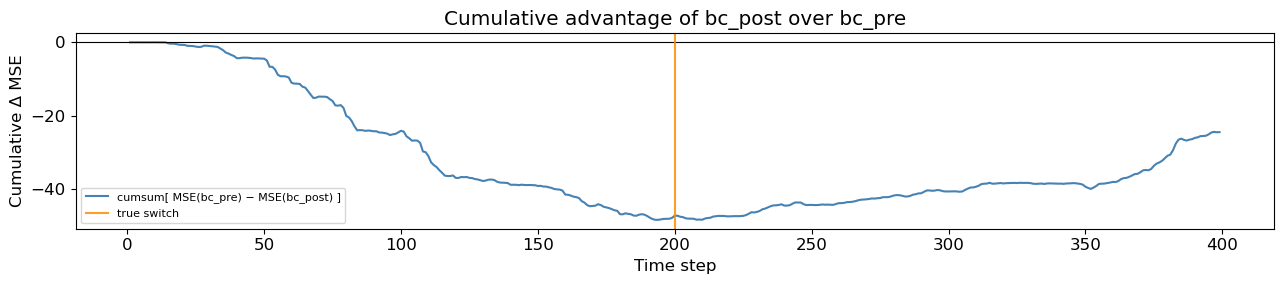

In [107]:
cumsum_delta = np.cumsum(delta)

fig, ax = plt.subplots(figsize=(13, 3))
ax.plot(t_ax, cumsum_delta, lw=1.5, color="steelblue",
        label="cumsum[ MSE(bc_pre) − MSE(bc_post) ]")
ax.axhline(0, color="k", lw=0.8)
for gt in switch_times:
    ax.axvline(gt, color="darkorange", lw=1.5, ls="-", alpha=0.85,
               label="true switch" if gt == switch_times[0] else None)
ax.set_xlabel("Time step")
ax.set_ylabel("Cumulative Δ MSE")
ax.set_title("Cumulative advantage of bc_post over bc_pre")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()